In [70]:
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
from metrics import calculate_per_class_metrics, calculate_overall_metrics


def softmax(logits):
    """Transform logits (raw scores) into probability distribution.

    Args:
        logits (list[float]): A list of outputs raw scores.

    Returns:
        list[float]: The probability distribution.
    """

    # Shift scores by largest value
    # Take their square to make them positive
    shifted = logits - np.max(logits)
    exp_scores = np.exp(shifted)
    return exp_scores / np.sum(exp_scores)


class Classifier:
    def __init__(self, inputs, outputs, learning_rate, seed=None):
        self.inputs = inputs
        self.outputs = outputs
        self.learning_rate = learning_rate
        self.rng = np.random.default_rng(seed)

        # One row of weights + one bias per class, initialized with random values from norm distr centered 0
        # Shape of outputs * inputs
        self.weights = self.rng.normal(loc=0, scale=0.01, size=(outputs, inputs))
        self.biases = np.zeros(outputs)

    def predict_probabilities(self, input_data):
        """Get class probabilities, for the input data.

        Args:
            input_data (list[float]): The input image, flattened to a vector and filtered to binary b&w.
        
        Returns:
            list[float]: The probability distribution provided by softmax().
        """
        
        x = np.asarray(input_data, dtype=float)
        # The dot product of the weights matrix and the input vector (+biases) produces the logits vector straight away
        logits = np.dot(self.weights, x) + self.biases
        return softmax(logits)

    def predict(self, input_data):
        return int(np.argmax(self.predict_probabilities(input_data)))

    def train(self, train_data, epochs=5):
        for epoch in range(epochs):
            print(f"Training epoch: {epoch+1}")
            total_loss=0.0
            # Iterate through the randomly shuffled train data
            for index in self.rng.permutation(len(train_data)):
                data = train_data[index]
                x = np.asarray(data["input"], dtype=float)
                label = int(data["label"])

                logits = np.dot(self.weights, x) + self.biases
                probabilities = softmax(logits)

                # One-hot target: 1 for the correct class, 0 for all others.
                target = np.zeros(self.outputs)
                target[label] = 1.0

                # Categorical cross-entropy
                eps = 1e-15
                safe_probabilities = np.clip(probabilities, eps, 1.0)
                loss = -np.sum(target * np.log(safe_probabilities))
                total_loss += loss

                # Derivative of loss with respect to probabilities: dL/dp_i = -y_i / p_i.
                d_loss_d_probabilities = -target / safe_probabilities

                # Softmax Jacobian: J[i, j] = dp_i / dz_j.
                softmax_jacobian = (np.diag(probabilities) - np.outer(probabilities, probabilities))
                # This Jacobian matrix will be symmetric to its diagonal, J = J^T

                # Chain rule: dL/dz = (dL/dp) * (dp/dz)
                gradient_logits = np.dot(d_loss_d_probabilities, softmax_jacobian)
                # Softmax case: gradient = probabilities - target

                # dL/dw_i = (dL/dz_i) * (dz_i/dw_i) = (dL/dz_i) * x_i
                # Weight update: W = W - α * (dL/dz_i) * x_i
                self.weights -= self.learning_rate * np.outer(gradient_logits, x)
                # Since (dz_i/db_i) = 1 we can just use gradient_logits
                # dL/db_i = (dL/dz_i) * (dz_i/db_i) = (dL/dz_i) * 1
                self.biases -= self.learning_rate * gradient_logits

            temp_confusion_matrix = classifier.test(full_test_data)
            temp_overall_metrics = calculate_overall_metrics(temp_confusion_matrix)
            print(f"Epoch {epoch + 1} loss: {total_loss / len(train_data):.4f}")
            print("=================================================================")

    def fast_train(self, train_data, epochs=5):
        for epoch in range(epochs):
            print(f"Training epoch: {epoch+1}")
            # Iterate through the randomly shuffled train data
            for index in self.rng.permutation(len(train_data)):
                data = train_data[index]
                x = np.asarray(data["input"], dtype=float)
                label = int(data["label"])

                logits = np.dot(self.weights, x) + self.biases
                probabilities = softmax(logits)

                # As stated above in train(), in the softmax case: gradient = probabilities - target
                gradient = probabilities.copy()
                gradient[label] -= 1

                # dL/dw_i = (dL/dz_i) * (dz_i/dw_i) = (dL/dz_i) * x_i
                self.weights -= self.learning_rate * np.outer(gradient, x)
                # dL/db_i = (dL/dz_i) * (dz_i/db_i) = (dL/dz_i) * 1
                self.biases -= self.learning_rate * gradient

    def test(self, test_data):
        accurate_predictions = 0
        confusion_matrix = np.zeros((10, 10), dtype=int)
        for data in test_data:
            inputs = data['input']
            expected = data['label']

            prediction = self.predict(inputs)

            accurate_predictions += 1 if prediction == expected else 0
            confusion_matrix[expected][prediction] += 1
        accuracy = accurate_predictions / len(test_data)
        print(f"Accuracy: {accuracy}")
        return confusion_matrix

In [71]:
"""Preprocess images into binary b&w, flat vectors.

Args:
    input_data (list[list[float]]): The input image, 8 bit b&w matrix.

Returns:
    list[float]: Binary b&w vector of the pixels.
"""
def image_preprocess(example):
    img = np.array(example["image"]) / 255.0
    img = (img > 0.5).astype(int)
    example["input"] = img.flatten()
    return example

dataset = load_dataset("ylecun/mnist")
dataset = dataset.map(image_preprocess)

full_train_data = dataset["train"]
full_test_data = dataset["test"]

classifier = Classifier(inputs=28*28, outputs=10, learning_rate=0.1, seed=69)
classifier.train(train_data=full_train_data, epochs=50)
confusion_matrix = classifier.test(full_test_data)

Training epoch: 1
Accuracy: 0.8745
{'precision': 0.8796026430407992, 'recall': 0.8745, 'fscore': 0.8729021721345578}
Epoch 1 loss: 1.1699
Training epoch: 2
Accuracy: 0.8657
{'precision': 0.8853289965239708, 'recall': 0.8657, 'fscore': 0.8689746760724082}
Epoch 2 loss: 1.1095
Training epoch: 3
Accuracy: 0.8779
{'precision': 0.8853142576048707, 'recall': 0.8779, 'fscore': 0.877551571550643}
Epoch 3 loss: 1.0997
Training epoch: 4
Accuracy: 0.8922
{'precision': 0.8979866867292285, 'recall': 0.8922, 'fscore': 0.8925562048973603}
Epoch 4 loss: 1.1050
Training epoch: 5
Accuracy: 0.8742
{'precision': 0.8845676700054235, 'recall': 0.8742, 'fscore': 0.8733419308471088}
Epoch 5 loss: 1.0807
Training epoch: 6
Accuracy: 0.8805
{'precision': 0.8875247434418996, 'recall': 0.8805, 'fscore': 0.8792923591542995}
Epoch 6 loss: 1.0708
Training epoch: 7
Accuracy: 0.8758
{'precision': 0.8881272775684272, 'recall': 0.8758, 'fscore': 0.8758395915262126}
Epoch 7 loss: 1.0661
Training epoch: 8
Accuracy: 0.8978


KeyboardInterrupt: 

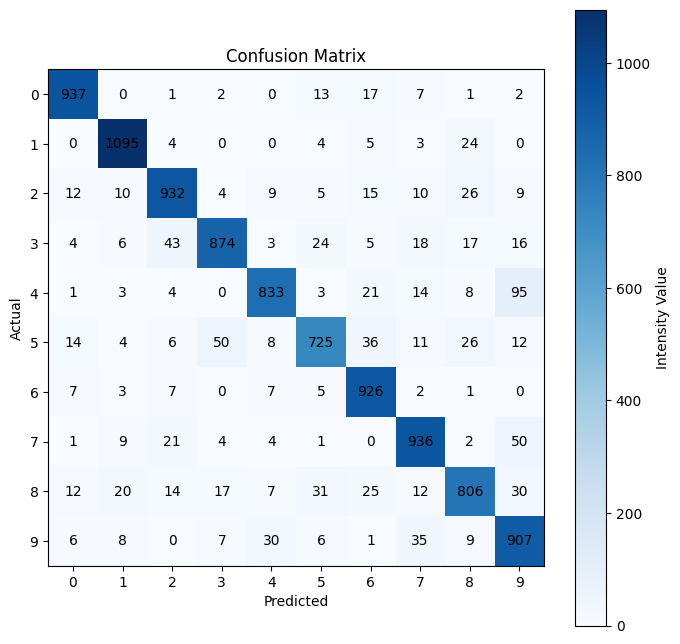

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))
cax = ax.imshow(confusion_matrix, cmap="Blues")

# plt.figure(figsize=(7, 7))

plt.imshow(confusion_matrix, cmap="Blues")

# Annotate each cell with its value
for i in range(10):
    for j in range(10):
        val = confusion_matrix[i, j]
        color = "black"
        ax.text(j, i, str(val), ha="center", va="center", color=color)

# Add colorbar and labels
plt.colorbar(label="Intensity Value")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks(range(10))
plt.yticks(range(10))

plt.show()

In [ ]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
from metrics import calculate_per_class_metrics, calculate_overall_metrics

per_class_metrics = calculate_per_class_metrics(confusion_matrix)
overall_metrics = calculate_overall_metrics(confusion_matrix)

{'precision': array([0.94265594, 0.94559585, 0.90310078, 0.91231733, 0.9245283 ,
       0.8873929 , 0.88106565, 0.89312977, 0.87608696, 0.80909902]), 'recall': array([0.95612245, 0.96475771, 0.90310078, 0.86534653, 0.84826884,
       0.81278027, 0.96659708, 0.91050584, 0.8275154 , 0.89890981]), 'fscore': array([0.94934144, 0.95508068, 0.90310078, 0.88821138, 0.88475836,
       0.84844939, 0.92185167, 0.9017341 , 0.85110876, 0.85164319])}
{'precision': 0.8981823777819625, 'recall': 0.8971, 'fscore': 0.896751871803873}


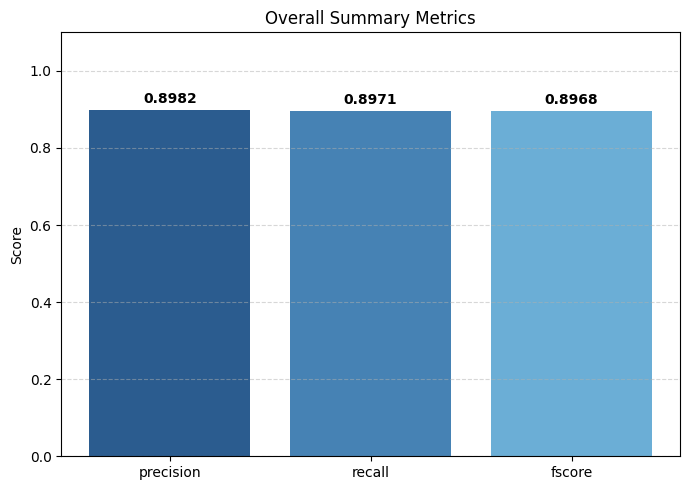

In [ ]:
plt.figure(figsize=(7, 5))
bars = plt.bar(overall_metrics.keys(), overall_metrics.values(), color=['#2b5c8f', '#4682b4', '#6baed6', '#9ecae1'])

# Annotate exact score on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold')

plt.ylim(0, 1.1)
plt.ylabel('Score')
plt.title('Overall Summary Metrics')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

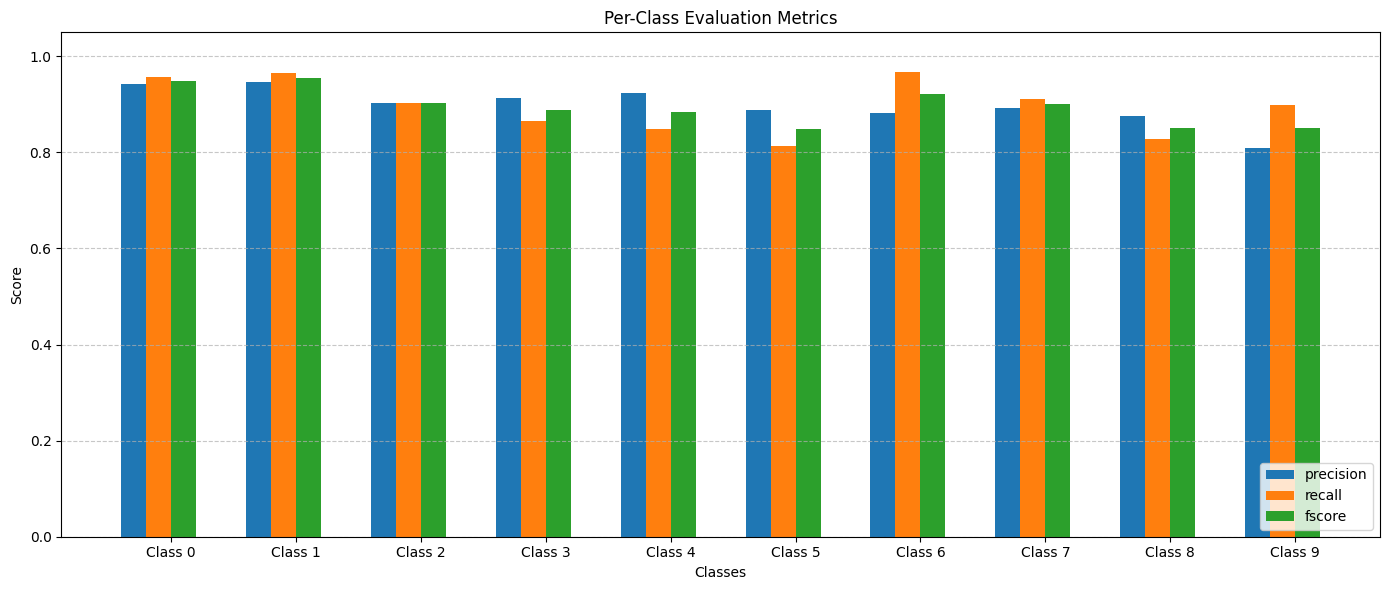

In [ ]:
num_classes = len(per_class_metrics['precision'])
classes = [f'Class {i}' for i in range(num_classes)]

x = np.arange(num_classes)
width = 0.2  # Bar width

plt.figure(figsize=(14, 6))

for i, (metric, values) in enumerate(per_class_metrics.items()):
    plt.bar(x + i * width, values, width, label=metric)

plt.xlabel('Classes')
plt.ylabel('Score')
plt.title('Per-Class Evaluation Metrics')
plt.xticks(x + width * 1.5, classes)
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

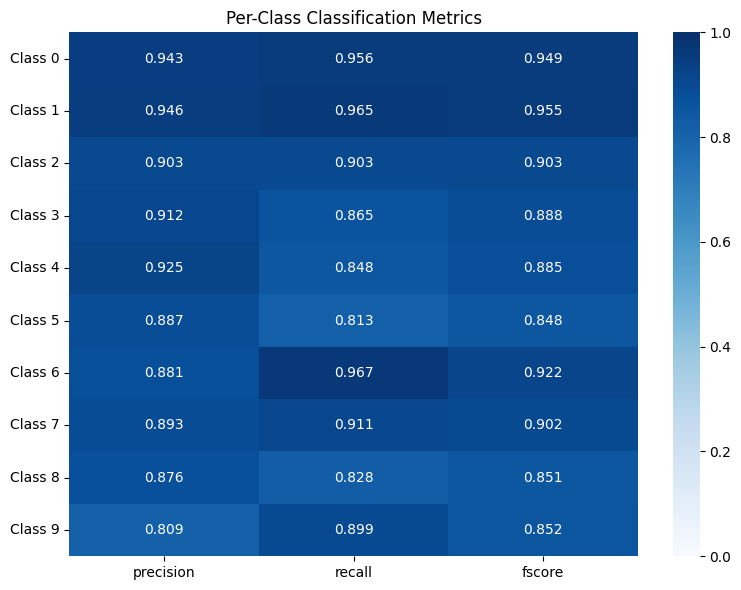

In [ ]:
import pandas as pd
import seaborn as sns

df_per_class = pd.DataFrame(per_class_metrics, index=[f'Class {i}' for i in range(10)])

plt.figure(figsize=(8, 6))
sns.heatmap(df_per_class, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1)
plt.title("Per-Class Classification Metrics")
plt.tight_layout()
plt.show()